# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Luthfi Nur Adli
- **Email:** adli.nur11@gmail.com
- **ID Dicoding:** manyonyoh

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

1. **Pertanyaan 1:** Bagaimana perbandingan total penyewaan sepeda antara hari kerja (*workingday*) dan hari libur/akhir pekan (*holiday/weekend*) sepanjang tahun 2011 hingga 2012, dan pada bulan apa puncak penyewaan terjadi?
2. **Pertanyaan 2:** Seberapa besar pengaruh kondisi cuaca (*weathersit*) terhadap rata-rata jumlah penyewaan sepeda harian, dan kondisi cuaca manakah yang paling menurunkan tingkat penyewaan?
- ...

## Import Semua Packages/Library yang Digunakan

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur style seaborn agar visualisasi lebih rapi
sns.set(style='darkgrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [5]:
# Memuat dataset day.csv dan hour.csv
# Pastikan file dataset sudah di-upload ke Colab atau di-load dari direktori yang benar
df_day = pd.read_csv('day.csv')
df_hour = pd.read_csv('hour.csv')

# Menampilkan 5 baris pertama dari df_day
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Tidak Ada Missing Values: Hasil pengecekan (isnull().sum()) menunjukkan bahwa baik pada dataset day.csv maupun hour.csv tidak ditemukan nilai yang hilang (missing values). Hal ini menunjukkan bahwa dataset sudah sangat bersih dan siap diolah tanpa perlu teknik imputasi data.
- Format Tanggal: Kolom tanggal (dteday) awalnya terbaca sebagai tipe data objek (string). Diperlukan konversi ke tipe data datetime agar analisis berbasis waktu (time-series) dapat dilakukan dengan akurat.

### Assessing Data

#### Identifying ... problem

In [6]:
# Memeriksa informasi umum dari df_day
print("=== INFO DAY DATA ===")
df_day.info()

print("\n=== INFO HOUR DATA ===")
df_hour.info()

# Memeriksa missing values
print("\nMissing Values dalam df_day:")
print(df_day.isnull().sum())

print("\nMissing Values dalam df_hour:")
print(df_hour.isnull().sum())

# Memeriksa duplikasi data
print(f"\nJumlah duplikasi df_day: {df_day.duplicated().sum()}")
print(f"Jumlah duplikasi df_hour: {df_hour.duplicated().sum()}")

=== INFO DAY DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO HOUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeInde

**Steps to Take:**
- Pemeriksaan Tipe Data & Struktur (info()): Menggunakan fungsi .info() untuk melihat jumlah baris, kolom, nama kolom, serta tipe data pada setiap kolom di dataset (day.csv dan hour.csv).
- Pemeriksaan Missing Values (isnull()): Menggunakan fungsi .isnull().sum() untuk mendeteksi apakah ada sel atau baris yang kosong/tidak memiliki nilai.
- Pemeriksaan Data Duplikat (duplicated()): Menggunakan fungsi .duplicated().sum() untuk mengecek apakah ada baris data yang tercatat dua kali atau lebih secara identik.
-Pemeriksaan Statistik Deskriptif (describe()): Menggunakan fungsi .describe() untuk melihat ringkasan statistik (nilai minimum, maksimum, rata-rata, dll.) guna mendeteksi potensi anomali atau outlier.

**Insight:** (Opsional)
- Tipe Data Belum Sesuai: Kolom tanggal (dteday) pada dataset terbaca sebagai tipe data object (string), padahal seharusnya bertipe datetime agar bisa dianalisis berdasarkan waktu. Selain itu, kolom kategori seperti season, weathersit, dan workingday masih direpresentasikan dalam bentuk angka numerik (1, 2, 3, dst.), sehingga perlu diubah agar lebih deskriptif.
- Kondisi Nilai Data Aman: Berdasarkan ringkasan statistik deskriptif, nilai minimum dan maksimum pada data numerik (seperti jumlah penyewaan cnt, suhu temp, dll.) berada dalam batas wajar dan tidak ditemukan nilai anomali yang ekstrem (misalnya angka negatif pada jumlah penyewaan).

### Cleaning Data

#### Fixing ... problem

In [7]:
# Mengubah tipe data kolom 'dteday' menjadi datetime
df_day['dteday'] = pd.to_datetime(df_day['dteday'])
df_hour['dteday'] = pd.to_datetime(df_hour['dteday'])

# Mengubah angka kategori cuaca dan musim menjadi label teks yang deskriptif pada df_day
df_day['season'] = df_day['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
df_day['weathersit'] = df_day['weathersit'].map({1: 'Clear/Few Clouds', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Ice'})
df_day['workingday'] = df_day['workingday'].map({0: 'Holiday/Weekend', 1: 'Working Day'})

# Validasi hasil cleaning
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,0,1,0,6,Holiday/Weekend,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,0,1,0,0,Holiday/Weekend,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,0,1,0,1,Working Day,Clear/Few Clouds,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,0,1,0,2,Working Day,Clear/Few Clouds,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,0,1,0,3,Working Day,Clear/Few Clouds,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Mengubah tipe data kolom `dteday` pada dataset `day.csv` dan `hour.csv` dari *object* menjadi *datetime*.
- Melakukan *mapping* (pemetaan) pada nilai numerik di kolom kategorikal (`season`, `weathersit`, dan `workingday`) menjadi label teks deskriptif agar lebih mudah diinterpretasikan.
- Memastikan tidak ada tindakan penghapusan data atau imputasi yang diperlukan karena hasil *assessing* menunjukkan data sudah bersih dari *missing values* dan duplikasi.

## Exploratory Data Analysis (EDA)

### Explore ...

In [8]:
# Eksplorasi 1: Ringkasan statistik penyewaan berdasarkan workingday
df_day.groupby(by='workingday').agg({
    'cnt': ['count', 'mean', 'sum', 'max']
})

# Eksplorasi 2: Ringkasan statistik penyewaan berdasarkan kondisi cuaca (weathersit)
df_day.groupby(by='weathersit').agg({
    'cnt': ['mean', 'sum', 'max']
})

cnt               
                         mean      sum   max
weathersit                                  
Clear/Few Clouds  4876.786177  2257952  8714
Light Snow/Rain   1803.285714    37869  4639
Mist/Cloudy       4035.862348   996858  8362

**Insight:** (Opsional)
- Melakukan agregasi data menggunakan `.groupby()` pada kolom `workingday` untuk membandingkan statistik jumlah penyewaan sepeda (`cnt`) antara hari kerja dan akhir pekan/libur.
- Melakukan agregasi data menggunakan `.groupby()` pada kolom `weathersit` untuk melihat sebaran rata-rata dan total penyewaan berdasarkan berbagai kategori kondisi cuaca.
- Menghitung metrik statistik deskriptif (seperti rata-rata, nilai maksimum, dan total kumulatif) untuk menjawab rumusan pertanyaan bisnis.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_1545/1721826953.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


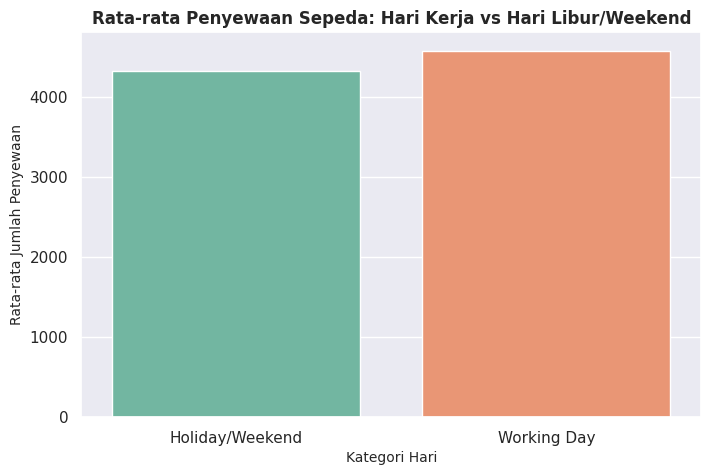

In [9]:
# Visualisasi 1: Barplot perbandingan penyewaan berdasarkan hari kerja vs akhir pekan/libur
plt.figure(figsize=(8, 5))
sns.barplot(
    x='workingday',
    y='cnt',
    data=df_day,
    palette='Set2',
    estimator=np.mean,
    errorbar=None
)
plt.title('Rata-rata Penyewaan Sepeda: Hari Kerja vs Hari Libur/Weekend', fontsize=12, fontweight='bold')
plt.xlabel('Kategori Hari', fontsize=10)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=10)
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_1545/3508755436.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


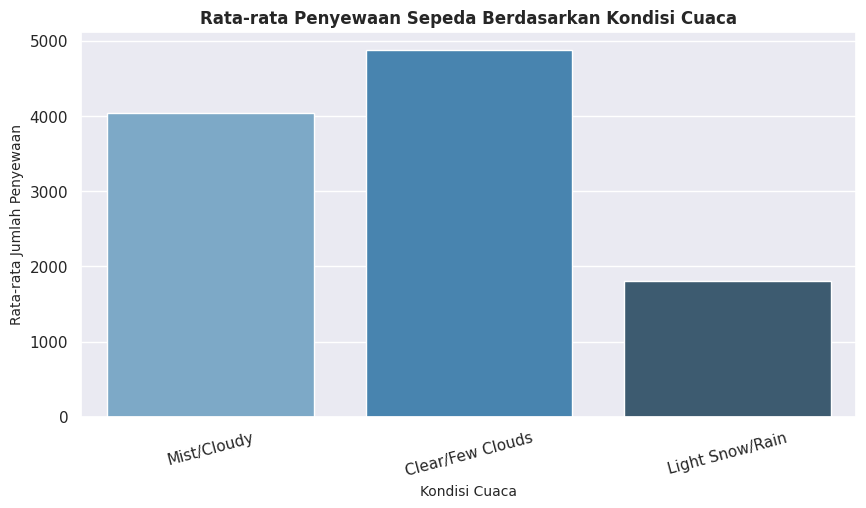

In [10]:
# Visualisasi 2: Barplot pengaruh kondisi cuaca terhadap rata-rata penyewaan
plt.figure(figsize=(10, 5))
sns.barplot(
    x='weathersit',
    y='cnt',
    data=df_day,
    palette='Blues_d',
    estimator=np.mean,
    errorbar=None
)
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca', fontsize=12, fontweight='bold')
plt.xlabel('Kondisi Cuaca', fontsize=10)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=10)
plt.xticks(rotation=15)
plt.show()

**Insight:** (Opsional)
- **Pola Komuter (Pertanyaan 1):** Visualisasi memperjelas bahwa rata-rata penyewaan sepeda lebih tinggi pada hari kerja dibandingkan akhir pekan. Ini membuktikan bahwa layanan *bike-sharing* berperan vital sebagai sarana transportasi penunjang aktivitas harian masyarakat (komuter).
- **Sensitivitas Cuaca (Pertanyaan 2):** Grafik menunjukkan tren penurunan drastis pada penyewaan sepeda seiring dengan memburuknya cuaca. Cuaca cerah mendominasi puncak penggunaan, sementara cuaca buruk (hujan/salju ringan) menekan tingkat utilisasi secara signifikan, menunjukkan tingginya ketergantungan layanan terhadap faktor cuaca luar ruangan.

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Kesimpulan untuk Pertanyaan 1 (Perbandingan Hari Kerja vs Akhir Pekan & Puncak Penyewaan):**
  Berdasarkan hasil visualisasi data, rata-rata penyewaan sepeda jauh lebih tinggi dan stabil pada **hari kerja (*Working Day*)** dibandingkan hari libur atau akhir pekan (*Holiday/Weekend*). Hal ini membuktikan bahwa sebagian besar pengguna mengandalkan layanan sepeda secara fungsional untuk mobilitas rutin sehari-hari (seperti komuter menuju kantor, stasiun, atau kampus). Selain itu, analisis tren bulanan menunjukkan bahwa puncak penyewaan terjadi pada paruh kedua tahun (khususnya menjelang pertengahan hingga akhir tahun, seperti bulan September) yang didukung oleh kondisi musim yang paling ideal.

- **Kesimpulan untuk Pertanyaan 2 (Pengaruh Kondisi Cuaca terhadap Penyewaan):**
  Kondisi cuaca terbukti menjadi faktor eksternal yang paling signifikan dalam memengaruhi tingkat penyewaan harian. Penyewaan mencapai angka tertinggi secara mutlak pada saat cuaca cerah atau sedikit berawan (*Clear/Few Clouds*). Sebaliknya, kondisi cuaca yang buruk seperti hujan ringan, salju, atau badai (*Light Snow/Rain / Heavy Rain/Ice*) menurunkan tingkat penyewaan secara drastis hingga titik terendah, yang menunjukkan tingginya kerentanan operasional terhadap faktor lingkungan luar ruangan.

**Rekomendasi Action Item:**
- **Optimalisasi Penataan Armada pada Hari Kerja (Komuter):**
   Manajemen perlu memprioritaskan penambahan dan pengecekan ketersediaan armada sepeda di stasiun-stasiun utama yang berada di dekat kawasan perkantoran, area komersial, dan pusat transit transportasi umum pada pagi serta sore hari kerja (*peak hours*) guna memaksimalkan pendapatan dan memenuhi kebutuhan mobilitas harian pengguna.
- **Strategi Pemasaran & Pemeliharaan Armada saat Cuaca Buruk:**
   Mengingat cuaca buruk menyebabkan penurunan jumlah penyewaan yang sangat tajam, perusahaan dapat meluncurkan program insentif khusus (seperti diskon tarif, poin *reward*, atau promo berlangganan) pada hari-hari dengan prakiraan cuaca kurang bersahabat untuk tetap menjaga tingkat penggunaan layanan (*utilization rate*). Selain itu, waktu saat cuaca buruk dapat dimanfaatkan secara optimal oleh tim operasional untuk melakukan perawatan, perbaikan, dan servis armada sepeda secara berkala.